# Midwest rent model

Listings are from 2018 and 2019, so every dollar figure here is a historical asking rent. The scope is the Midwest (about 12,000 usable listings) because the Chicago metro alone has only about 700. All training logic lives in `src/model.py`; this notebook runs it and shows the results.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import model

pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

## Data and engineered features

Price per square foot and cost per bedroom are engineered here for description and for the match score, but they are computed from rent, so they are not used as predictors.

In [2]:
frame = model.load_midwest()
print(f'{len(frame):,} usable Midwest listings, {int(frame.flagged.sum()):,} flagged, {int(frame.is_chicago_metro.sum()):,} in the Chicago metro')
frame[['price', 'square_feet', 'price_per_sqft', 'cost_per_bedroom', 'distance_from_campus_miles', 'amenity_count']].describe().T

11,977 usable Midwest listings, 466 flagged, 721 in the Chicago metro


,count,mean,std,min,25%,50%,75%,max
price,"11,977.000","1,116.194",546.249,224.000,775.000,975.000,"1,325.000","15,000.000"
square_feet,"11,977.000",948.405,395.385,200.000,715.000,890.000,"1,105.000","12,000.000"
price_per_sqft,"11,977.000",1.237,0.541,0.047,0.898,1.089,1.413,9.398
cost_per_bedroom,"11,977.000",707.370,385.198,133.333,437.500,615.000,862.500,"4,000.000"
distance_from_campus_miles,"11,977.000",306.898,150.874,0.723,246.272,293.976,388.446,890.966
amenity_count,"9,721.000",4.026,2.748,1.000,2.000,3.000,5.000,17.000


## Skew

A log transform is applied wherever it brings skewness closer to zero.

In [3]:
skew = model.skew_report(frame)
pd.DataFrame(skew).T

,raw_skew,log_skew,use_log,transform
price,3.764,0.554,True,log
square_feet,5.297,0.228,True,log
distance_from_campus_miles,0.673,-2.218,False,log1p


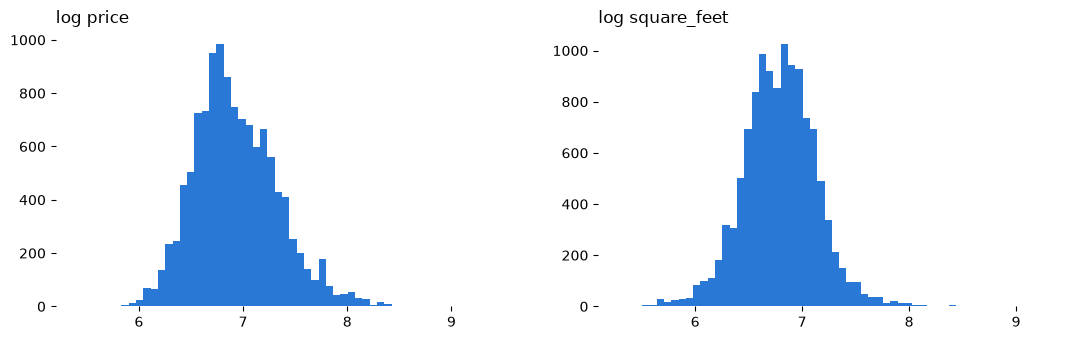

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for axis, column in zip(axes, ['price', 'square_feet']):
    axis.hist(np.log(frame[column]), bins=60, color='#2a78d6')
    axis.set_title(f'log {column}', loc='left')
    for spine in axis.spines.values():
        spine.set_visible(False)
plt.tight_layout()

## Fit both models, with and without flagged rows

`train_all` splits 20% of rows off as a held-out set, stratified on the Chicago metro indicator, runs 5-fold cross validation on the training set, and fits multiple linear regression and a random forest twice: once excluding flagged rows and once including them.

In [5]:
results = model.train_all(write=False)
variants = results['variants']

In [6]:
rows = []
for key, variant in variants.items():
    for subset in ['held_out_all', 'chicago_metro', 'outside_chicago_metro', 'near_campus']:
        rows.append({'variant': key, 'subset': subset, 'model': 'Baseline (mean rent)', **variant['baseline'][subset]})
        for kind in model.MODEL_KINDS:
            rows.append({'variant': key, 'subset': subset, 'model': model.MODEL_NAMES[kind], **variant['models'][kind]['evaluation'][subset]})
comparison = pd.DataFrame(rows)
comparison.pivot_table(index=['variant', 'subset', 'model'], values=['rmse', 'mae', 'r2', 'rows'], sort=False)

rmse  \
variant           subset                model                                  
excluding_flagged held_out_all          Baseline (mean rent)         619.611   
                                        Multiple linear regression   419.113   
                                        Random forest                387.994   
                  chicago_metro         Baseline (mean rent)       1,639.761   
                                        Multiple linear regression   976.388   
                                        Random forest              1,160.278   
                  outside_chicago_metro Baseline (mean rent)         495.818   
                                        Multiple linear regression   359.259   
                                        Random forest                280.905   
                  near_campus           Baseline (mean rent)       1,755.582   
                                        Multiple linear regression 1,039.398   
                                        Random forest              1,238.115   
including_flagged held_out_all          Baseline (mean rent)         612.831   
                                        Multiple linear regression   418.151   
                                        Random forest                379.547   
                  chicago_metro         Baseline (mean rent)       1,565.973   
                                        Multiple linear regression   954.569   
                                        Random forest              1,095.312   
                  outside_chicago_metro Baseline (mean rent)         492.717   
                                        Multiple linear regression   357.443   
                                        Random forest                276.684   
                  near_campus           Baseline (mean rent)       1,666.027   
                                        Multiple linear regression 1,009.802   
                                        Random forest              1,161.008   

                                                                       mae  \
variant           subset                model                                
excluding_flagged held_out_all          Baseline (mean rent)       385.705   
                                        Multiple linear regression 254.849   
                                        Random forest              174.333   
                  chicago_metro         Baseline (mean rent)       864.610   
                                        Multiple linear regression 587.912   
                                        Random forest              413.022   
                  outside_chicago_metro Baseline (mean rent)       357.015   
                                        Multiple linear regression 234.896   
                                        Random forest              160.033   
                  near_campus           Baseline (mean rent)       972.467   
                                        Multiple linear regression 624.532   
                                        Random forest              456.518   
including_flagged held_out_all          Baseline (mean rent)       383.439   
                                        Multiple linear regression 254.105   
                                        Random forest              172.303   
                  chicago_metro         Baseline (mean rent)       816.877   
                                        Multiple linear regression 550.597   
                                        Random forest              388.607   
                  outside_chicago_metro Baseline (mean rent)       355.724   
                                        Multiple linear regression 235.146   
                                        Random forest              158.471   
                  near_campus           Baseline (mean rent)       907.825   
                                        Multiple linear regression 578.307   
                                        R

## Cross validation on the training set

In [7]:
pd.DataFrame([
    {'variant': key, 'model': model.MODEL_NAMES[kind], **{f'{metric}_{stat}': variant['models'][kind]['cross_validation'][metric][stat] for metric in ('rmse', 'mae', 'r2') for stat in ('mean', 'std')}}
    for key, variant in variants.items() for kind in model.MODEL_KINDS
])

,variant,model,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std
0,excluding_flagged,Multiple linear regression,379.902,19.270,249.563,9.154,0.483,0.024
1,excluding_flagged,Random forest,294.155,21.414,172.739,4.159,0.690,0.025
2,including_flagged,Multiple linear regression,380.967,10.973,251.258,3.968,0.479,0.014
3,including_flagged,Random forest,293.218,16.851,172.869,5.350,0.692,0.017


## Residuals: does error grow with price?

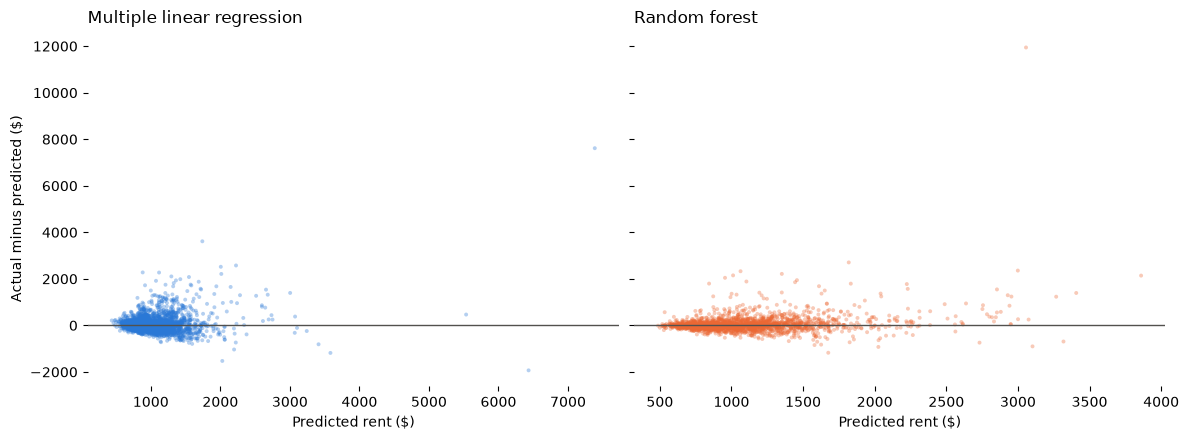

In [8]:
chosen = variants['excluding_flagged']
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for axis, kind in zip(axes, model.MODEL_KINDS):
    plot = chosen['models'][kind]['plot']
    axis.scatter(plot['predicted'], plot['actual'] - plot['predicted'], s=8, alpha=0.35, color=model.SERIES_COLORS[kind], edgecolors='none')
    axis.axhline(0, color='#52514e', linewidth=1)
    axis.set_title(model.MODEL_NAMES[kind], loc='left')
    axis.set_xlabel('Predicted rent ($)')
    for spine in axis.spines.values():
        spine.set_visible(False)
axes[0].set_ylabel('Actual minus predicted ($)')
plt.tight_layout()

In [9]:
pd.concat({model.MODEL_NAMES[kind]: pd.DataFrame(chosen['models'][kind]['error_by_price']) for kind in model.MODEL_KINDS})

band  rows     mae  \
Multiple linear regression 0       $325 to $735   468 177.068   
                           1       $735 to $895   454 152.557   
                           2     $895 to $1,095   462 162.853   
                           3   $1,095 to $1,415   456 205.343   
                           4  $1,415 to $15,000   460 576.413   
Random forest              0       $325 to $735   468 121.417   
                           1       $735 to $895   454  93.636   
                           2     $895 to $1,095   462 103.978   
                           3   $1,095 to $1,415   456 140.591   
                           4  $1,415 to $15,000   460 411.920   

                              median_percent_error  coverage  
Multiple linear regression 0                 0.240     0.684  
                           1                 0.143     0.910  
                           2                 0.141     0.929  
                           3                 0.135     0.873  
                           4                 0.256     0.652  
Random forest              0                 0.125     0.720  
                           1                 0.073     0.859  
                           2                 0.076     0.868  
                           3                 0.085     0.893  
                           4                 0.145     0.722

Absolute dollar error rises with rent in both models, and the top rent band carries most of it. Modelling log rent keeps percentage error steadier than dollar error, which is why the prediction interval is applied on the log scale and calibrated separately within bands of predicted rent.

## Prediction interval

The interval comes from out-of-fold residuals on the training set (the 10th and 90th percentiles, per band of predicted rent), and coverage is then checked on the untouched held-out set.

In [10]:
pd.concat({model.MODEL_NAMES[kind]: pd.DataFrame(chosen['models'][kind]['coverage_by_predicted_band']) for kind in model.MODEL_KINDS})

band  rows  coverage
Multiple linear regression 0        under $799   443     0.860
                           1      $799 to $925   465     0.774
                           2    $925 to $1,096   477     0.797
                           3  $1,096 to $1,315   474     0.802
                           4     $1,315 and up   441     0.814
Random forest              0        under $782   459     0.810
                           1      $782 to $914   445     0.820
                           2    $914 to $1,089   477     0.809
                           3  $1,089 to $1,333   459     0.810
                           4     $1,333 and up   460     0.809

## What drives rent

Linear effects are the dollar change at the median rent for the stated change, with everything else held fixed. Permutation importance is the rise in held-out RMSE, in dollars, when that feature is shuffled.

In [11]:
from src.model import importance_table
pd.DataFrame(importance_table(chosen))[['feature', 'linear_dollars', 'linear_change', 'linear_permutation_dollars', 'forest_permutation_dollars', 'forest_impurity_share']]

,feature,linear_dollars,linear_change,linear_permutation_dollars,forest_permutation_dollars,forest_impurity_share
0,Square footage,54.381,10% more square footage,153.086,154.186,0.362
1,Distance from campus,-2.908,10 more miles from campus,15.489,111.201,0.223
2,Bathrooms,193.212,one more bathroom,66.970,86.917,0.098
3,Bedrooms,-55.588,"one more bedroom, same square footage",-3.616,35.589,0.058
4,State,NaN,ranges from -112 to +342 dollars across catego...,20.200,24.388,0.063
5,Chicago metro,503.358,inside the Chicago metro rather than elsewhere...,66.702,24.265,0.027
6,Amenity count,75.785,one more listed amenity of any kind,136.663,7.446,0.030
7,Amenity: Pool,1.849,"Pool listed, which also adds one to the amenit...",6.503,6.177,0.011
8,Amenity: Refrigerator,-89.401,"Refrigerator listed, which also adds one to th...",11.511,5.944,0.010
9,Amenity: Storage,30.374,"Storage listed, which also adds one to the ame...",2.235,4.752,0.009


## Chicago metro fully held out

Training only on non-Chicago Midwest rows and testing on every Chicago metro row shows how much the model depends on seeing local rows.

In [12]:
transfer = results['transfer']
pd.DataFrame({'Baseline (Midwest mean)': transfer['baseline'], 'Baseline (Illinois mean)': transfer['illinois_baseline'], **{model.MODEL_NAMES[kind]: metrics for kind, metrics in transfer['models'].items()}}).T

,rmse,mae,r2,rows
Baseline (Midwest mean),"1,135.918",689.867,-0.392,655.000
Baseline (Illinois mean),"1,137.598",691.618,-0.396,655.000
Multiple linear regression,"1,001.968",681.856,-0.083,655.000
Random forest,"1,074.747",695.505,-0.246,655.000


## Deployed fair rent estimates

In [13]:
results['estimates']['value_label'].value_counts()

value_label
within    9663
below     1165
above     1149
Name: count, dtype: int64